# Group 4: Bank Marketing Campaign Prediction
DSE301B Feature Engineering (CA3). Data: UCI Bank Marketing, `data/bank-additional-full.csv`.

Run all cells from top to bottom. Charts are also saved in the `out/` folder.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import RFE, mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, StratifiedKFold
import os; os.makedirs('out', exist_ok=True)

## Dataset
We drop `duration` (known only after the call, so it leaks the answer) and make a 0/1 target.

(41188, 19) yes rate 0.113 | nulls: 0


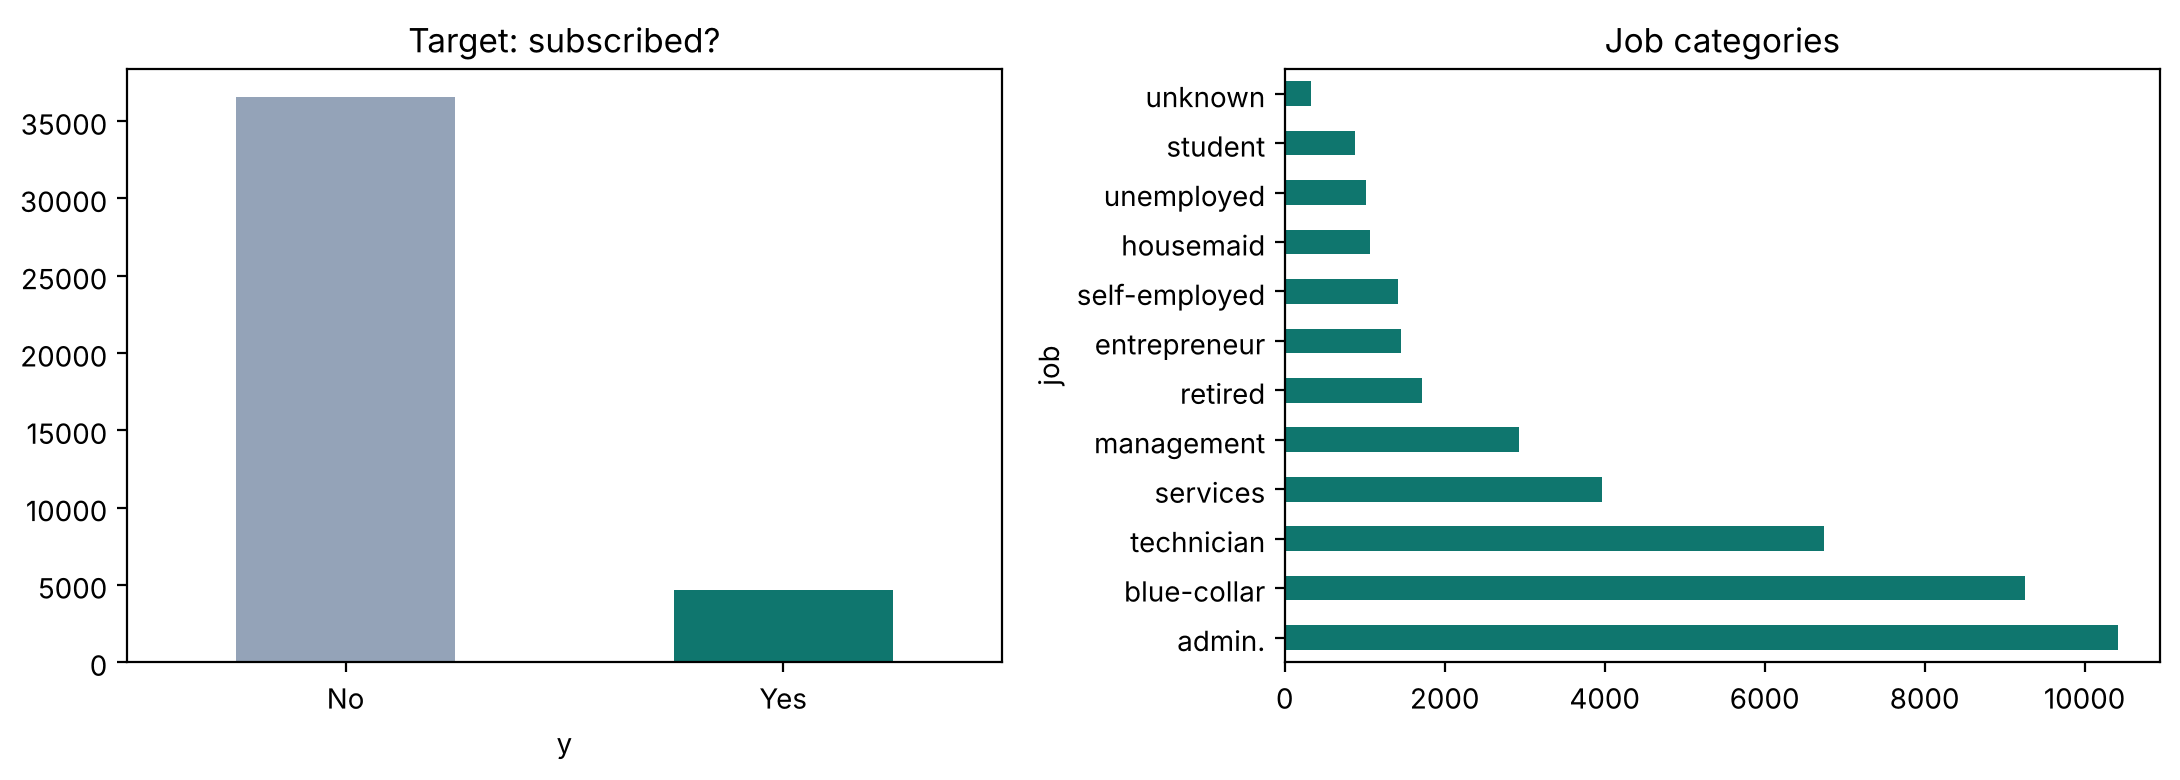

In [2]:
df = pd.read_csv('data/bank-additional-full.csv', sep=';').drop(columns='duration')
y = (df.pop('y') == 'yes').astype(int)
print(df.shape, 'yes rate %.3f' % y.mean(), '| nulls:', df.isna().sum().sum())
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
y.map({0: 'No', 1: 'Yes'}).value_counts().plot.bar(ax=ax[0], rot=0, color=['#94a3b8', '#0f766e'], title='Target: subscribed?')
df.job.value_counts().plot.barh(ax=ax[1], color='#0f766e', title='Job categories')
plt.tight_layout(); plt.savefig('out/data.png', dpi=150); plt.show()

## Task 1: Identify categorical and numerical attributes

In [3]:
cat = df.select_dtypes(exclude='number').columns.tolist()
num = df.select_dtypes('number').columns.tolist()
print(len(cat), 'categorical:', cat)
print(len(num), 'numerical:', num)

10 categorical: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']
9 numerical: ['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']


## Task 2: One-hot encoding (job, marital, education, contact)

In [4]:
oh = ['job', 'marital', 'education', 'contact']
X = pd.get_dummies(df, columns=oh, dtype=int)
rest = [c for c in cat if c not in oh]
X = pd.get_dummies(X, columns=rest, drop_first=True, dtype=int)
print(X.shape)
print({c: int(X.columns.str.startswith(c + '_').sum()) for c in oh})

(41188, 56)
{'job': 12, 'marital': 4, 'education': 8, 'contact': 2}


## Task 3: Transform numerical features (log for skew, then standardize)

skew before: {'campaign': 4.76, 'previous': 3.83}
skew after:  {'campaign': 1.35, 'previous': 2.59}


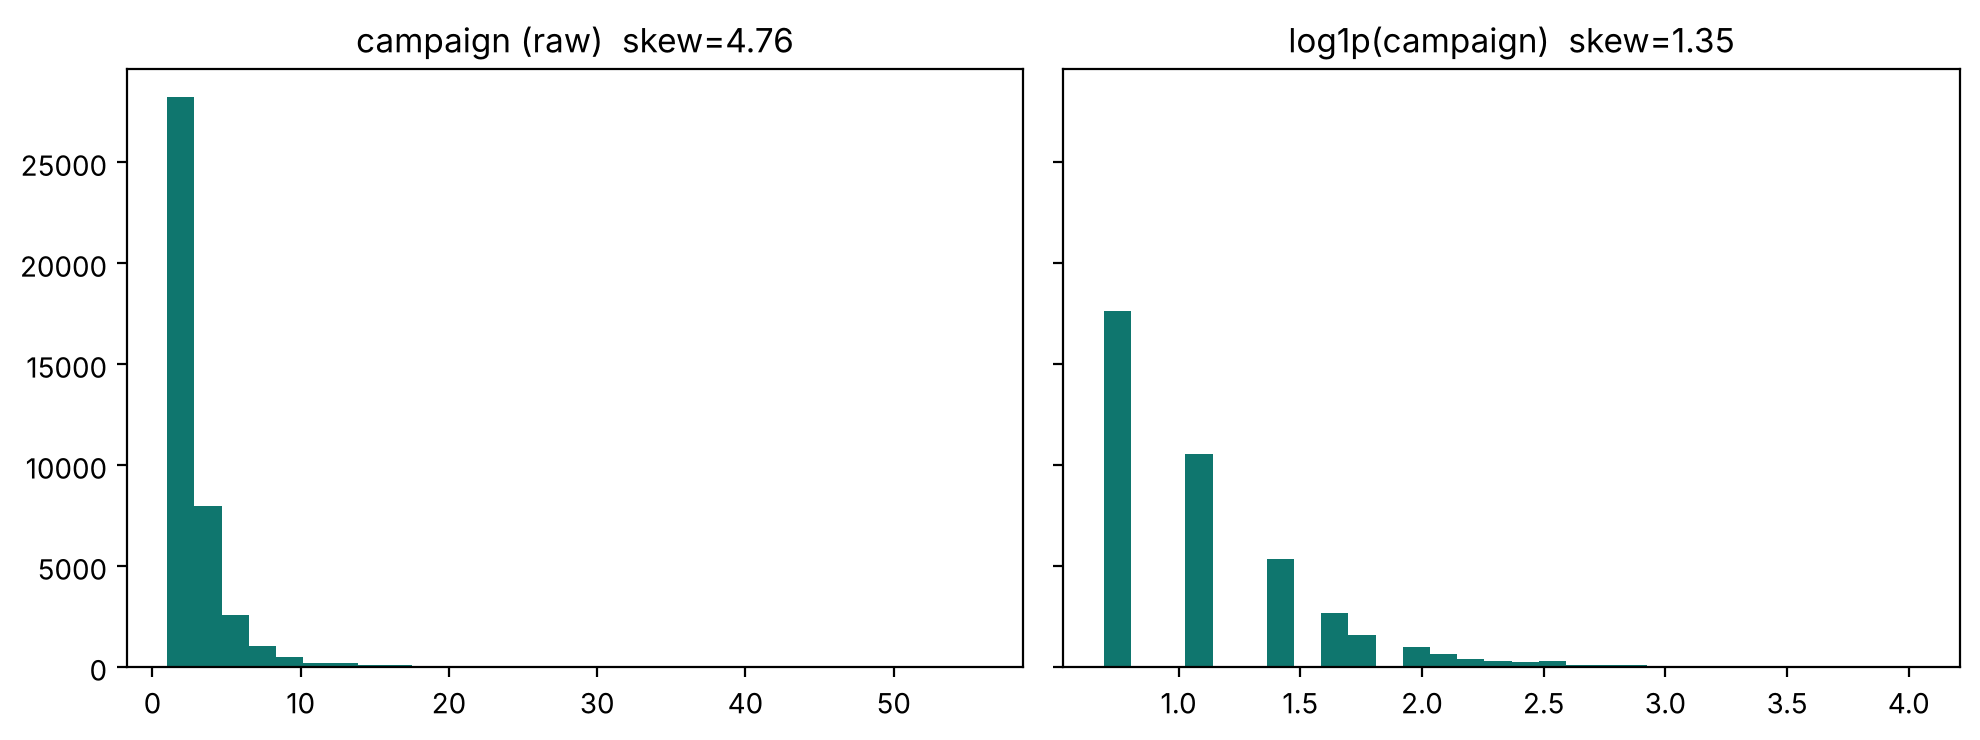

In [5]:
print('skew before:', df[['campaign', 'previous']].skew().round(2).to_dict())
X[['campaign', 'previous']] = np.log1p(X[['campaign', 'previous']])
print('skew after: ', X[['campaign', 'previous']].skew().round(2).to_dict())   # measured before scaling (scaling does not change skew)
X[num] = StandardScaler().fit_transform(X[num])
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for a, d, t in zip(ax, [df.campaign, np.log1p(df.campaign)], ['campaign (raw)', 'log1p(campaign)']):
    a.hist(d, bins=30, color='#0f766e'); a.set_title(f'{t}  skew={d.skew():.2f}')
plt.tight_layout(); plt.savefig('out/transform.png', dpi=150); plt.show()

## Task 4: Correlation analysis of numerical features

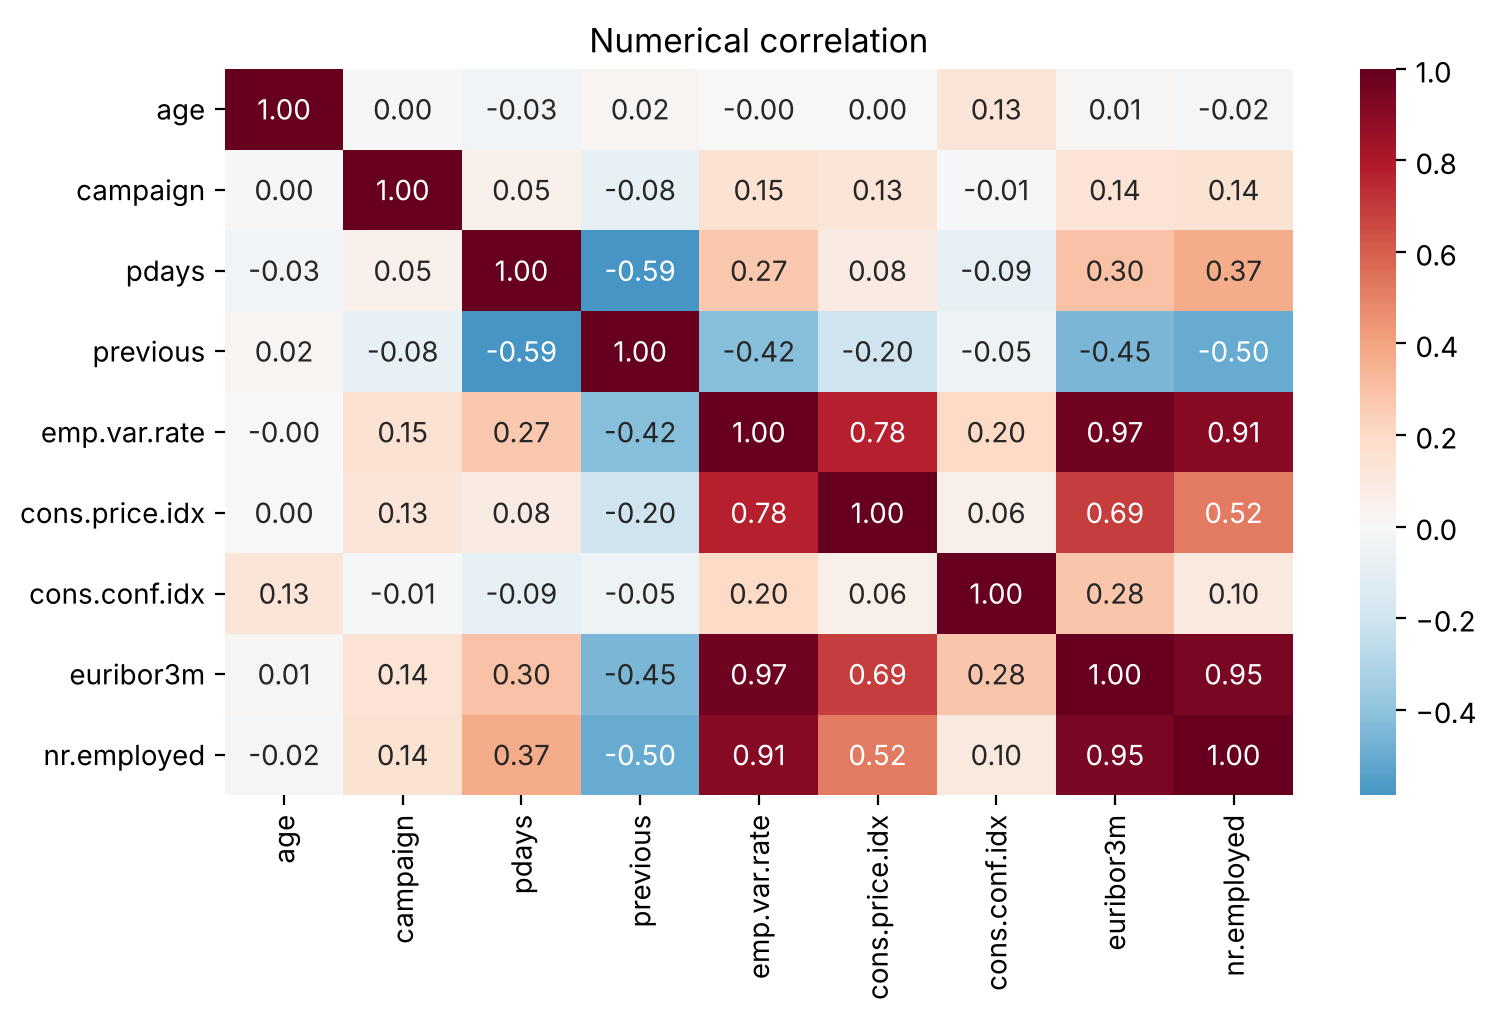

In [6]:
plt.figure(figsize=(8, 5.2))
sns.heatmap(df[num].corr(), annot=True, fmt='.2f', cmap='RdBu_r', center=0)
plt.title('Numerical correlation'); plt.tight_layout(); plt.savefig('out/corr.png', dpi=150); plt.show()

## Task 5: Wrapper (RFE) and hybrid (mutual information filter, then RFE) selection

In [7]:
lr = LogisticRegression(max_iter=1000, class_weight='balanced')
rfe = lambda d: d.columns[RFE(lr, n_features_to_select=15).fit(d, y).support_]
wrap = rfe(X)                                                                   # wrapper
top = X.columns[np.argsort(mutual_info_classif(X, y, random_state=0))[-30:]]    # filter
hyb = rfe(X[top])                                                               # hybrid
print('Wrapper:', list(wrap)); print('Hybrid:', list(hyb)); print('Common:', sorted(set(wrap) & set(hyb)))

Wrapper: ['emp.var.rate', 'cons.price.idx', 'euribor3m', 'job_retired', 'job_student', 'contact_telephone', 'default_unknown', 'month_aug', 'month_dec', 'month_jun', 'month_mar', 'month_may', 'month_nov', 'poutcome_nonexistent', 'poutcome_success']
Hybrid: ['marital_single', 'month_mar', 'month_dec', 'job_retired', 'month_may', 'month_oct', 'default_unknown', 'contact_telephone', 'poutcome_nonexistent', 'poutcome_success', 'pdays', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m']
Common: ['cons.price.idx', 'contact_telephone', 'default_unknown', 'emp.var.rate', 'euribor3m', 'job_retired', 'month_dec', 'month_mar', 'month_may', 'poutcome_nonexistent', 'poutcome_success']


## Task 6: Model performance before and after feature selection

               Features     F1    AUC
All                56.0  0.451  0.792
Wrapper RFE        15.0  0.455  0.793
Hybrid MI+RFE      15.0  0.450  0.791


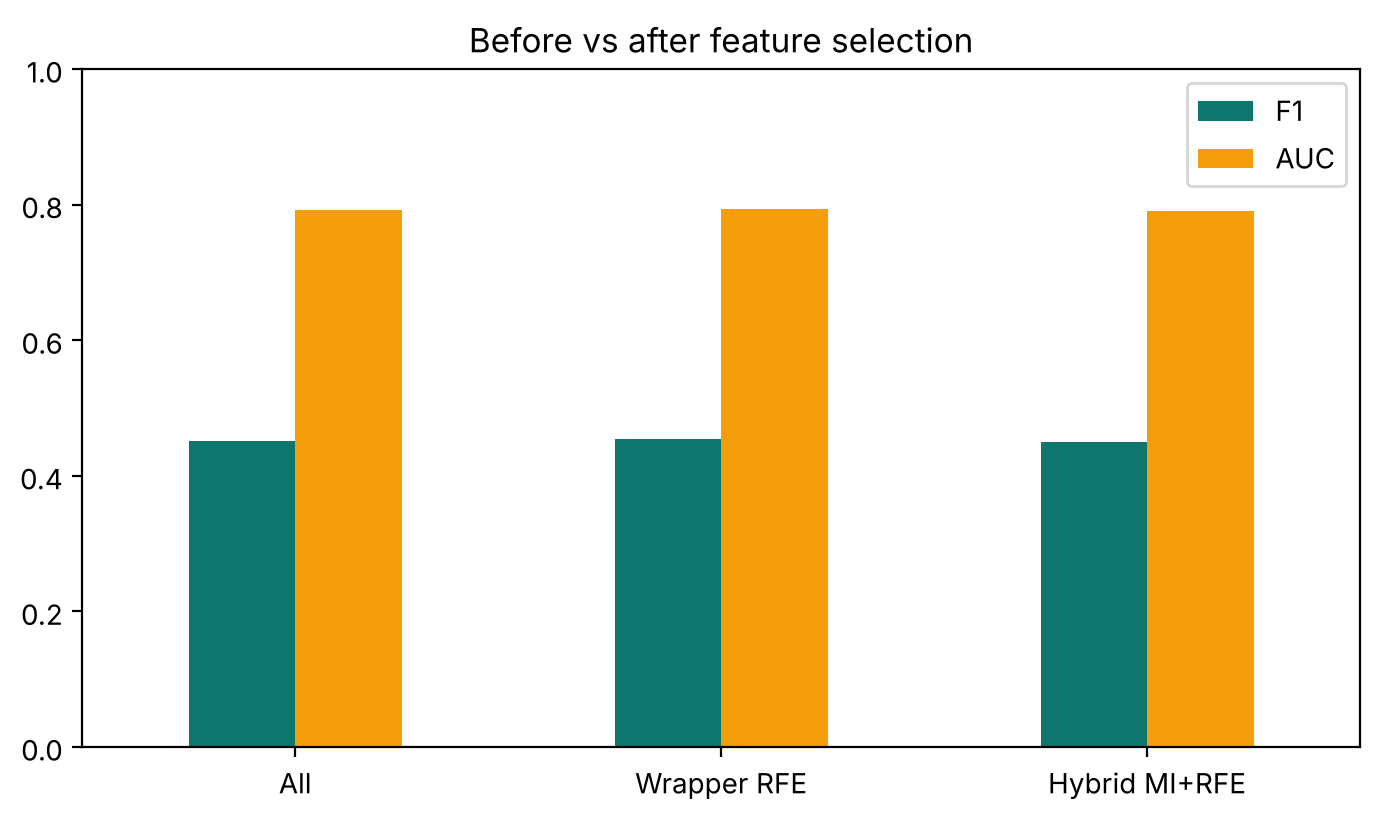

In [8]:
cv = StratifiedKFold(5, shuffle=True, random_state=0)
sc = lambda c, m: cross_val_score(lr, X[c], y, cv=cv, scoring=m).mean()
sets = {'All': X.columns, 'Wrapper RFE': wrap, 'Hybrid MI+RFE': hyb}
r = pd.DataFrame({n: (len(c), sc(c, 'f1'), sc(c, 'roc_auc')) for n, c in sets.items()}, index=['Features', 'F1', 'AUC']).T
print(r.round(3))
r[['F1', 'AUC']].plot.bar(rot=0, ylim=(0, 1), color=['#0f766e', '#f59e0b'], figsize=(7, 4.2))
plt.title('Before vs after feature selection'); plt.tight_layout(); plt.savefig('out/compare.png', dpi=150); plt.show()

## Conclusion
The dataset goes from 56 to 15 features with the same F1 and AUC. Wrapper and hybrid agree on 11 features.